# Datos de Puntualidad Aerolínea
* Objetivo: Crear un df para predecir los minutos de demora en función de las variables del DF inicial

In [1]:
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#Importar un Data Set
df_completo = pd.read_excel('Datos Aerolinea copy.xlsx')
column_name=['Opnumber',
    'Canceled',
    'Delay',]
df=df_completo.drop(columns=column_name)

#### Paso intermedio de cambiar los STDs y los STAs en datos categoricos. Clasificación por franjas  

In [3]:
# 1. Convertir las columnas tipo 'object' a tipo datetime STD
# Asegúrate de usar el nombre exacto de la columna en tu df

std_dt=pd.to_datetime(df['Stdhhmm'], format='%H:%M:%S')

# 2. Redondear hacia abajo al bloque de 60 minutos más cercano
inicio_franja = std_dt.dt.floor('60min')
# Sumar 30 minutos para calcular el fin de la franja
fin_franja = inicio_franja + pd.Timedelta(minutes=60)

# 3. Crear la nueva columna combinando ambos tiempos como texto
df['Std_Franja_60m'] = inicio_franja.dt.strftime('%H:%M') + '-' + fin_franja.dt.strftime('%H:%M')


# 1. Convertir las columnas tipo 'object' a tipo datetime STA
# Asegúrate de usar el nombre exacto de la columna en tu df

std_dt=pd.to_datetime(df['Stahhmm'], format='%H:%M:%S')

# 2. Redondear hacia abajo al bloque de 60 minutos más cercano
inicio_franja = std_dt.dt.floor('60min')
# Sumar 30 minutos para calcular el fin de la franja
fin_franja = inicio_franja + pd.Timedelta(minutes=60)

# 3. Crear la nueva columna combinando ambos tiempos como texto
df['Sta_Franja_60m'] = inicio_franja.dt.strftime('%H:%M') + '-' + fin_franja.dt.strftime('%H:%M')

df=df.drop(columns=
['Stdhhmm',
'Stahhmm'])

In [4]:
#Obtener los tipos de datos de un Data Frame
df.dtypes

Legdate                datetime64[ns]
Vehicleregistration            object
Depstring                      object
Arrstring                      object
Route                          object
Blockoffdiff                    int64
Pax                             int64
Std_Franja_60m                 object
Sta_Franja_60m                 object
dtype: object

## 1. Descriptiva de Datos Numéricos

In [5]:
#Descriptiva de los datos Numéricos
df.describe()

,Legdate,Blockoffdiff,Pax
count,12171,12171.000000,12171.000000
mean,2022-09-13 20:21:21.340892160,19.298250,143.151097
min,2022-01-20 00:00:00,-245.000000,0.000000
25%,2022-06-25 00:00:00,-4.000000,137.000000
50%,2022-09-24 00:00:00,0.000000,154.000000
75%,2022-12-10 00:00:00,15.000000,164.000000
max,2023-02-16 00:00:00,1568.000000,180.000000
std,NaN,67.270325,34.383701


<Axes: ylabel='Frequency'>

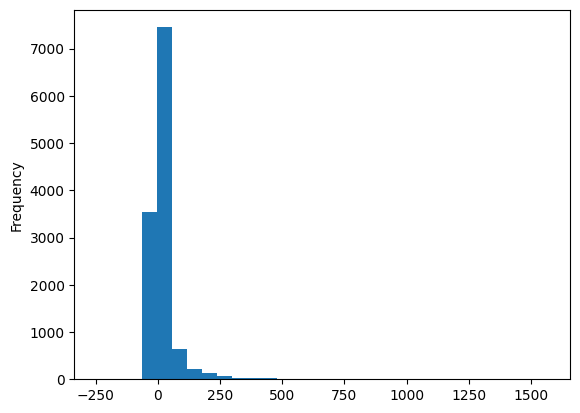

In [6]:
df['Blockoffdiff'].plot.hist(bins=30)

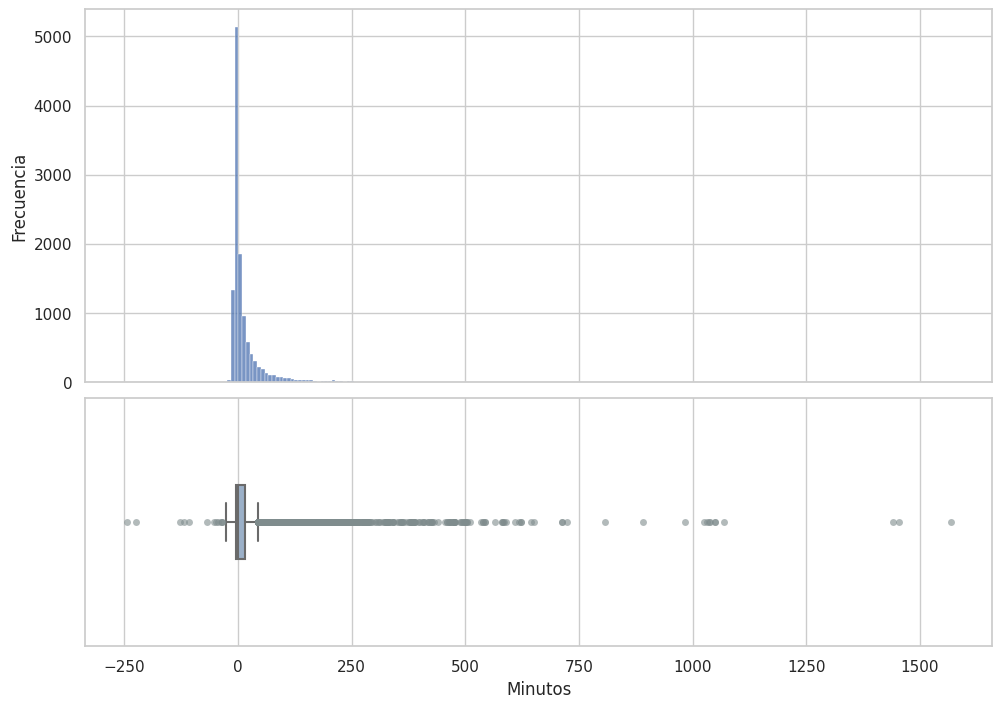

In [7]:
#Versión mas estilizada que la anterior

import seaborn as sns
import matplotlib.pyplot as plt

# Fondo limpio
sns.set_theme(style="whitegrid", rc={'figure.figsize':(11.7, 8.27)})

# Creación del lienzo
f, (ax_hist, ax_box) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.6, .4)})

# 1. Histograma estilizado
sns.histplot(df['Blockoffdiff'], ax=ax_hist, color='#4C72B0', edgecolor='white')

# 2. Boxplot CORREGIDO (horizontal) y ESTILIZADO
sns.boxplot(
    x=df['Blockoffdiff'],  # Usar 'x=' es lo que fuerza a que sea horizontal
    ax=ax_box, 
    width=0.3,               # Hace la caja más delgada (menos tosca)
    color='#93B0CF',         # Un color suave que combine con el histograma
    linewidth=1.5,           # Líneas de los bigotes más definidas
    flierprops={             # Estilo para los datos atípicos (outliers)
        'marker': 'o',
        'markersize': 5,
        'markerfacecolor': '#7F8C8D',
        'markeredgecolor': 'none',
        'alpha': 0.6         # Semi-transparencia
    }
)

# 3. Limpieza de textos y ejes
ax_hist.set(xlabel='', ylabel='Frecuencia')
ax_box.set(xlabel='Minutos')

# Elimina el espacio extra entre ambos gráficos para unirlos más
plt.subplots_adjust(hspace=0.05)

plt.show()

## 2. Descriptiva de Datos Categóricos

In [8]:
df.describe(include='object')

,Vehicleregistration,Depstring,Arrstring,Route,Std_Franja_60m,Sta_Franja_60m
count,12095,12171,12171,12171,12171,12171
unique,6,14,12,51,23,24
top,HK-5394,BOG,BOG,MDE-BOG,17:00-18:00,12:00-13:00
freq,2578,3317,3326,1251,1167,1000


In [9]:
# Selecciona solo las columnas de tipo 'object' (categóricas)
cols_categoricas = df.select_dtypes(include='object').columns

# Itera sobre cada columna e imprime los valores
for col in cols_categoricas:
    print(f"--- Conteo para: {col} ---")
    print(df[col].value_counts())
    print("\n")

--- Conteo para: Vehicleregistration ---
Vehicleregistration
HK-5394    2578
HK-5396    2566
HK-5413    1883
HK-5402    1759
HK-5395    1725
HK-5393    1584
Name: count, dtype: int64


--- Conteo para: Depstring ---
Depstring
BOG    3317
MDE    3095
CTG    1774
SMR    1382
CLO    1246
ADZ     702
PEI     447
BAQ      91
MTR      82
CUC      31
FOR       1
LPA       1
SAW       1
AXM       1
Name: count, dtype: int64


--- Conteo para: Arrstring ---
Arrstring
BOG    3326
MDE    3064
CTG    1787
SMR    1387
CLO    1241
ADZ     717
PEI     451
BAQ      83
MTR      82
CUC      31
LPA       1
FOR       1
Name: count, dtype: int64


--- Conteo para: Route ---
Route
MDE-BOG    1251
BOG-MDE    1238
MDE-CTG     712
CTG-MDE     700
CTG-BOG     667
BOG-CTG     662
SMR-BOG     561
BOG-SMR     558
MDE-SMR     540
SMR-MDE     538
CLO-BOG     515
BOG-CLO     515
BOG-ADZ     341
ADZ-BOG     328
PEI-CTG     269
CTG-PEI     265
CLO-MDE     250
MDE-CLO     246
CLO-ADZ     242
ADZ-CLO     240
SMR-PEI     

# 3. Histograma de los Datos Numéricos

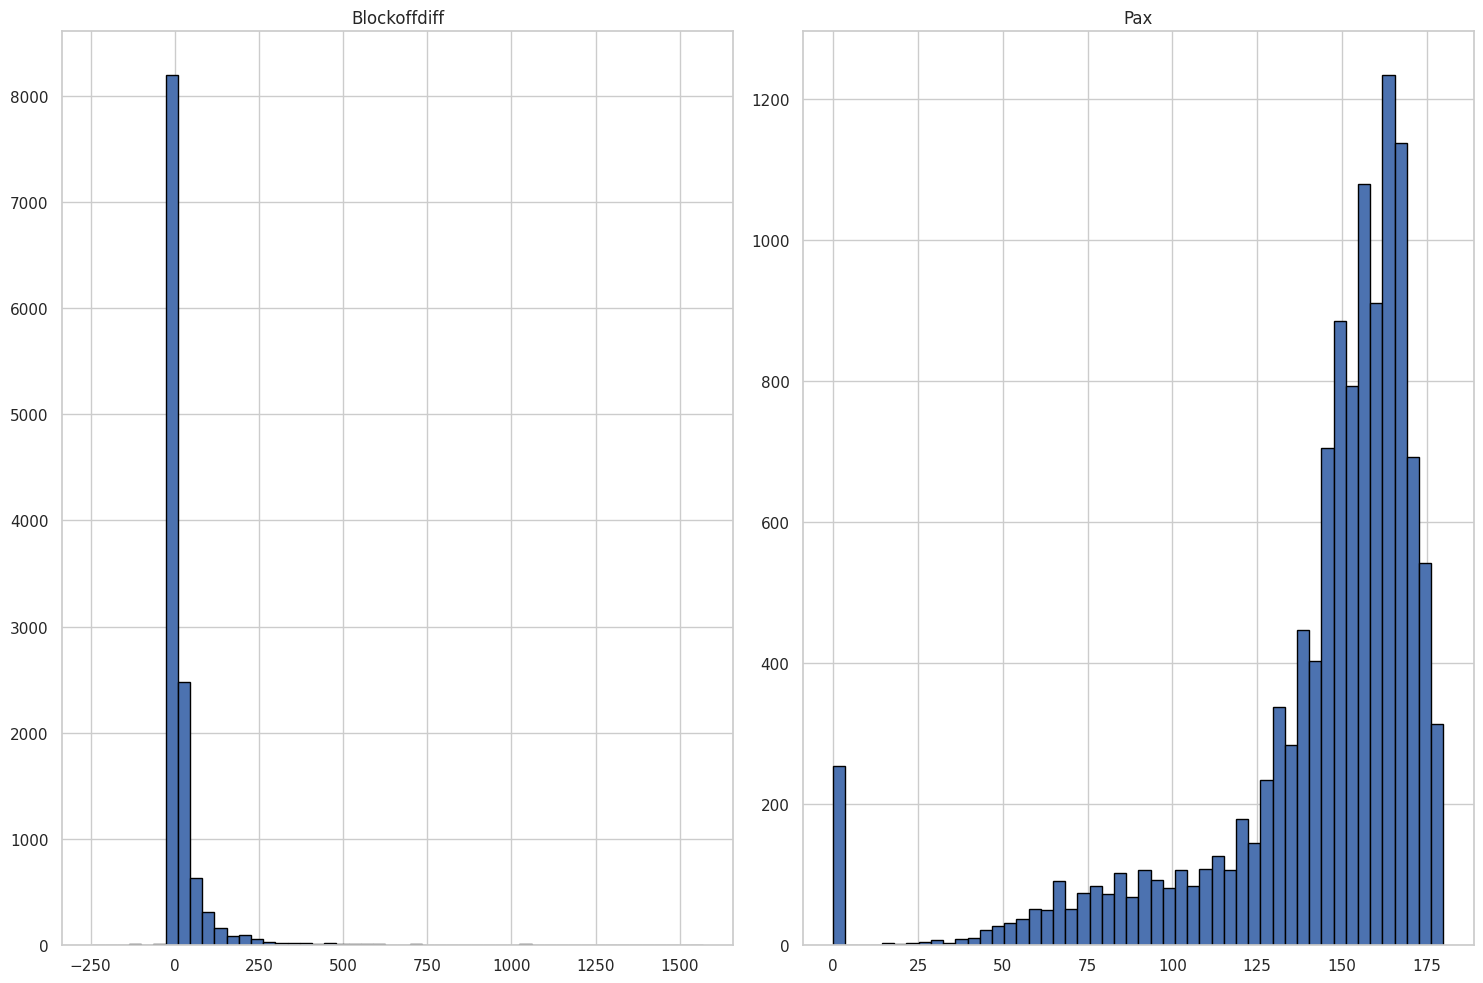

In [10]:
# Tu lista de columnas
columnas = [
    'Blockoffdiff', 
    'Pax'
]

# Genera los 5 histogramas directamente desde el DataFrame
df[columnas].hist(figsize=(15, 10), bins=50, edgecolor='black', grid=True)

# Ahora plt sí está definido para ajustar el diseño y mostrar el gráfico
plt.tight_layout()
plt.show()

# 4. Escalamiento de datos numéricos
1. Validar el sesgo de los datos. El SESGO de los datos es hacia donde apunta la COLA mas larga de los datos

    Montaña Izquierda / Cola Derecha = Sesgo a la Derecha --> POSITIVO
    Montaña Derecha / Cola Izquierda = Sesgo a la Izquierda --> NEGATIVO

## Variables con sesgo NEGATIVO --> PAX Reflection and LOG

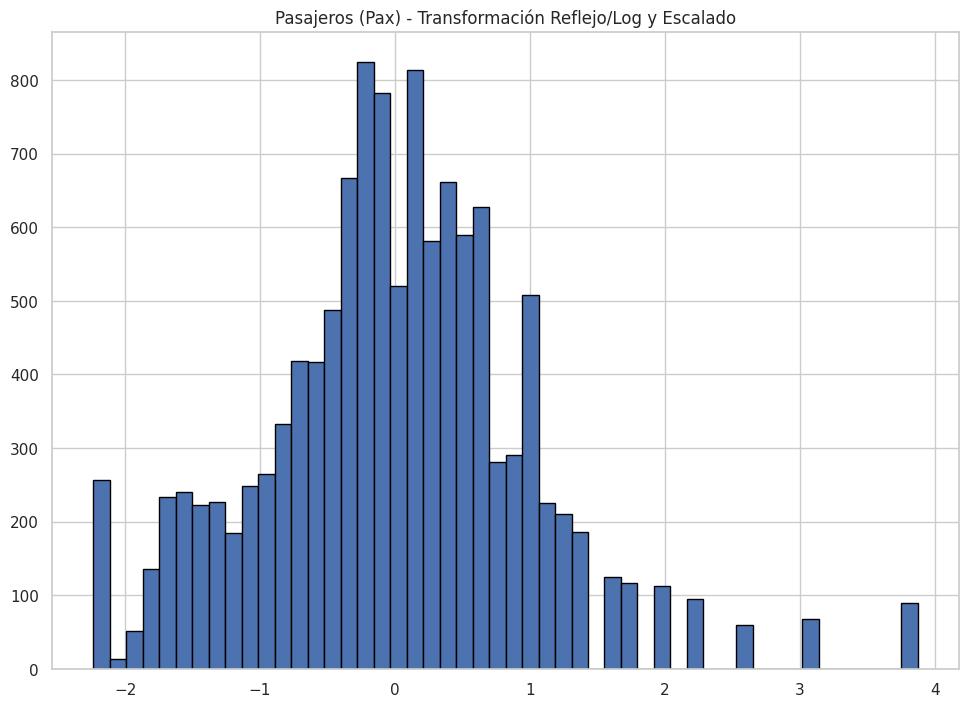

In [11]:
#Sesgo NEGATIVO // Transformación Tangente Hiperbólica
# 1. Crea una nueva columna que sea la transformación Tangente Hiperbólica
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. EL TRUCO DEL REFLEJO (Para tratar el sesgo negativo)
# Creamos una constante que sea un poco mayor al valor máximo de tus datos.
# Si el máximo de pasajeros es 180, usamos 181 para que ninguna resta dé cero.

constante_max = 181

# Restamos los pasajeros a la constante. Esto "voltea" la gráfica como en un espejo,
# convirtiendo el sesgo negativo en un sesgo positivo temporalmente.
df['Pax_reflejado'] = constante_max - df['Pax']

# 2. TRANSFORMACIÓN LOGARÍTMICA
# Ahora que la cola larga está a la derecha, el logaritmo funcionará perfectamente 
# para comprimir esa cola y darle a los datos una forma de campana de Gauss.
df['Pax_log'] = np.log(df['Pax_reflejado'])

# 3. ESCALAMIENTO (StandardScaler)
# Instancias el escalador
scaler = StandardScaler()

# Le aplicas el escalador a la nueva columna usando el doble corchete (Dataframe 2D)
df['Pax_escalado'] = scaler.fit_transform(df[['Pax_log']])

# 4. RE-INVERSIÓN DEL SENTIDO (Truco de Analista Senior)
# Al hacer el reflejo en el paso 1, invertimos la lógica: los vuelos más llenos quedaron 
# con los números más bajos. Para que tu modelo predictivo tenga lógica (valores altos = más pasajeros),
# multiplicamos la columna final por -1.
df['Pax_escalado_final'] = df['Pax_escalado'] * -1

# 5. Graficamos el resultado final para validar la corrección
df['Pax_escalado_final'].hist(bins=50, edgecolor='black')
plt.title("Pasajeros (Pax) - Transformación Reflejo/Log y Escalado")
plt.show()

## Variables con sesgo POSITIVO --> Blockoffdiff Yeo-Johnson

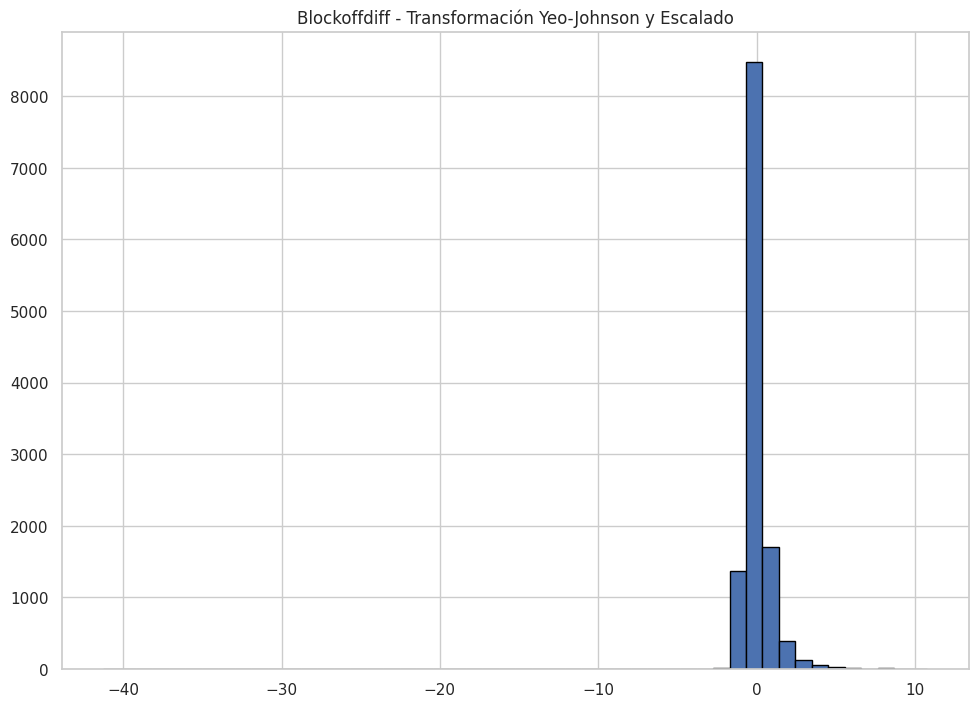

In [12]:
from sklearn.preprocessing import PowerTransformer
import matplotlib.pyplot as plt

# 1. Instancias la herramienta (el transformador)
# method='yeo-johnson' es el valor por defecto, diseñado específicamente para lidiar con ceros y negativos.
# standardize=True también es el valor por defecto, equivalente a usar StandardScaler inmediatamente después.
transformador_yeo = PowerTransformer(method='yeo-johnson', standardize=True)

# 2. Aplicas el transformador a tu columna
# Recuerda siempre usar DOBLE corchete [['columna']] para pasarle un DataFrame (2D) a Scikit-Learn.
df['Blockoffdiff_escalado'] = transformador_yeo.fit_transform(df[['Blockoffdiff']])

# 3. Graficamos el resultado para verificar
# Deberías ver que el sesgo positivo extremo se reduce drásticamente y los datos toman una forma más centrada.
df['Blockoffdiff_escalado'].hist(bins=50, edgecolor='black')
plt.title("Blockoffdiff - Transformación Yeo-Johnson y Escalado")
plt.show()

# 5. Escalamiento de datos Categóricos

In [13]:
#Pandas que aplique One-hot encoding específicamente a una o más columnas
df.nunique()

# Convertimos la aerolínea y el año en las "etiquetas" (Índice) de las filas
df_machine_learning = df.set_index(['Legdate', 'Route','Arrstring'])

# Aplicamos el One-Hot Encoding solo a las ganadoras
df_machine_learning = pd.get_dummies(df, columns=[
    'Vehicleregistration', 
    'Depstring',
    'Std_Franja_60m',
    'Sta_Franja_60m'])

# Eliminamos las columnas para limpiar la matriz
df_machine_learning = df_machine_learning.drop(columns=
    ['Blockoffdiff',
    'Pax',
    'Pax_reflejado',
    'Pax_log',
    'Pax_escalado'])


# Se obtiene el DF de los datos tanto categóricos como numéricos escalados
df_machine_learning.head()

,Legdate,Arrstring,Route,Pax_escalado_final,Blockoffdiff_escalado,Vehicleregistration_HK-5393,Vehicleregistration_HK-5394,Vehicleregistration_HK-5395,Vehicleregistration_HK-5396,Vehicleregistration_HK-5402,...,Sta_Franja_60m_14:00-15:00,Sta_Franja_60m_15:00-16:00,Sta_Franja_60m_16:00-17:00,Sta_Franja_60m_17:00-18:00,Sta_Franja_60m_18:00-19:00,Sta_Franja_60m_19:00-20:00,Sta_Franja_60m_20:00-21:00,Sta_Franja_60m_21:00-22:00,Sta_Franja_60m_22:00-23:00,Sta_Franja_60m_23:00-00:00
0,2022-01-20,BOG,MDE-BOG,-2.234908,1.117633,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2022-01-20,CTG,BOG-CTG,-2.234908,1.033343,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2022-01-26,MDE,BOG-MDE,-2.234908,0.895892,True,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,2022-02-16,LPA,SAW-LPA,-2.234908,-0.167006,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,2022-02-17,FOR,LPA-FOR,-2.234908,4.259229,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## Matriz de Covarianza

In [14]:
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# 1. Encontrar las columnas que cumplen la condición y limitar a las primeras 5
columnas_a_agregar = ['Pax_escalado_final', 
'Blockoffdiff_escalado']

df_numerico = df_machine_learning[columnas_a_agregar].copy()
df_numerico.T

covariance_matrix = np.cov(df_numerico.T)
covariance_matrix

array([[1.00008217, 0.0603224 ],
       [0.0603224 , 1.00008217]])

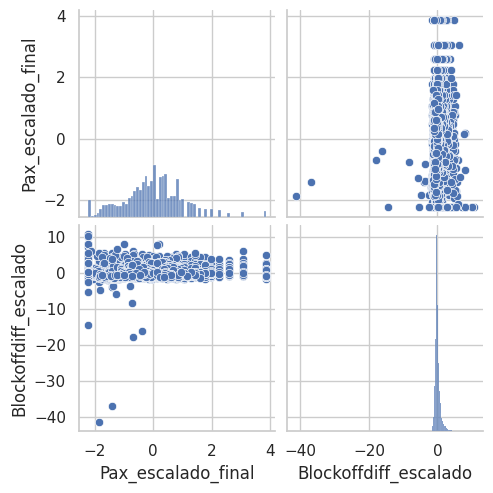

In [15]:
sns.pairplot(df_numerico)

# 6. PCA

In [16]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

variance_explained = []
for i in eigen_values:
    variance_explained.append((i/sum(eigen_values))*100)

print(variance_explained)

[np.float64(46.984127878792556), np.float64(53.015872121207444)]


In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(df_numerico)

pca.explained_variance_ratio_

array([0.53015872, 0.46984128])

## 7. Matriz de Características (o Feature Matrix)

In [18]:
# Ajustamos a 2 componentes y obtenemos las coordenadas matemáticas
pca_final = PCA(n_components=2)
coordenadas_pca = pca_final.fit_transform(df_numerico)

# Convertimos ese arreglo matemático en un Dataframe de Pandas estructurado
df_pca = pd.DataFrame(
    data=coordenadas_pca, 
    columns=['PC1', 'PC2'], 
    index=df_numerico.index # Clave: Esto mantiene 'airline_name' y 'year' intactos
)
df_pca

,PC1,PC2
0,-0.790032,-2.370604
1,-0.849634,-2.311002
2,-0.946827,-2.213810
3,-1.698409,-1.462227
4,1.431411,-4.592048
...,...,...
12166,0.102308,0.768692
12167,-0.659087,0.007296
12168,-1.144114,-0.262607
12169,-0.572371,0.914130


In [19]:
list(df_machine_learning.columns)

['Legdate',
 'Arrstring',
 'Route',
 'Pax_escalado_final',
 'Blockoffdiff_escalado',
 'Vehicleregistration_HK-5393',
 'Vehicleregistration_HK-5394',
 'Vehicleregistration_HK-5395',
 'Vehicleregistration_HK-5396',
 'Vehicleregistration_HK-5402',
 'Vehicleregistration_HK-5413',
 'Depstring_ADZ',
 'Depstring_AXM',
 'Depstring_BAQ',
 'Depstring_BOG',
 'Depstring_CLO',
 'Depstring_CTG',
 'Depstring_CUC',
 'Depstring_FOR',
 'Depstring_LPA',
 'Depstring_MDE',
 'Depstring_MTR',
 'Depstring_PEI',
 'Depstring_SAW',
 'Depstring_SMR',
 'Std_Franja_60m_00:00-01:00',
 'Std_Franja_60m_01:00-02:00',
 'Std_Franja_60m_03:00-04:00',
 'Std_Franja_60m_04:00-05:00',
 'Std_Franja_60m_05:00-06:00',
 'Std_Franja_60m_06:00-07:00',
 'Std_Franja_60m_07:00-08:00',
 'Std_Franja_60m_08:00-09:00',
 'Std_Franja_60m_09:00-10:00',
 'Std_Franja_60m_10:00-11:00',
 'Std_Franja_60m_11:00-12:00',
 'Std_Franja_60m_12:00-13:00',
 'Std_Franja_60m_13:00-14:00',
 'Std_Franja_60m_14:00-15:00',
 'Std_Franja_60m_15:00-16:00',
 'Std_

In [20]:
# Concatenamos (pegamos) las columnas del PCA junto a las columnas de dummies
# 1. Encontrar las columnas categóricas (eliminando las que no lo son)
columnas_out = [
    'Legdate',
    'Arrstring',
    'Route',
]
# Corrección: Aplicar drop() al DataFrame indicando las columnas a eliminar
df_dummies_categoricos = df_machine_learning.drop(columns=columnas_out)
df_entregable_ml = pd.concat([df_dummies_categoricos], axis=1)
df_entregable_ml

,Pax_escalado_final,Blockoffdiff_escalado,Vehicleregistration_HK-5393,Vehicleregistration_HK-5394,Vehicleregistration_HK-5395,Vehicleregistration_HK-5396,Vehicleregistration_HK-5402,Vehicleregistration_HK-5413,Depstring_ADZ,Depstring_AXM,...,Sta_Franja_60m_14:00-15:00,Sta_Franja_60m_15:00-16:00,Sta_Franja_60m_16:00-17:00,Sta_Franja_60m_17:00-18:00,Sta_Franja_60m_18:00-19:00,Sta_Franja_60m_19:00-20:00,Sta_Franja_60m_20:00-21:00,Sta_Franja_60m_21:00-22:00,Sta_Franja_60m_22:00-23:00,Sta_Franja_60m_23:00-00:00
0,-2.234908,1.117633,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,-2.234908,1.033343,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,-2.234908,0.895892,True,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
3,-2.234908,-0.167006,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,-2.234908,4.259229,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12166,0.615890,-0.471204,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
12167,-0.460886,-0.471204,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
12168,-0.994702,-0.623319,False,False,False,True,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
12169,0.241660,-1.051115,False,False,False,True,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [21]:
X = df.drop('Blockoffdiff_escalado', axis=1)
y = df['Blockoffdiff_escalado']

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=1a60b3ba-ebc9-46e8-8ab1-96cbe1b4a6bc' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>